# Por que a abstenção foi tão alta em 2026? — 1º turno da eleição presidencial

Análise com **dados públicos** do TSE (resultados e perfil do eleitorado por seção/zona/município) e do IBGE (Censo 2022).
Tudo é reproduzível: `src/prepare_data.py` agrega os arquivos brutos e este notebook lê as tabelas já agregadas em `data/processed/`.

## Resumo (todos os números abaixo foram calculados neste notebook a partir dos dados do TSE/IBGE)

* **A abstenção de 2026 (21,08%) é praticamente a mesma de 2022 (20,95%)**: +0,14 p.p. Ela é alta, mas dentro de uma tendência de duas décadas (16,8% em 2006).
  Então a pergunta "por que *tanta* abstenção?" tem um pressuposto que os dados não sustentam: não houve salto.
* **A abstenção não explica a diferença entre Flávio e Lula no 1º turno.** A margem é de ~2,2 mi de votos; a abstenção subiu +0,7 mi, enquanto Lula perdeu −3,4 mi e a direita ganhou +5,0 mi.
  Lula perdeu 3–4,5 p.p. de votos válidos em *todos* os decis de lulismo. A abstenção *caiu* nos redutos mais lulistas (Nordeste/Norte).
* **Por que a abstenção é estruturalmente alta:** ~13% do eleitorado tem voto facultativo (16–17, 70+, analfabetos), abstém 50% e gera 1/3 das abstenções; até os obrigatórios faltam 16%.
  Entre municípios, **onde a fatia de eleitores 70+ cresceu, a abstenção subiu mais**.
* **Fora do escopo** (sem dado aberto utilizado aqui): erro das pesquisas, clima, distância, voto dividido — ver seção 7.

**Perguntas**

1. Os números que circulam nas notícias batem com o TSE?
2. A abstenção de 2026 é mesmo anormal? Em relação a quê?
3. Ela subiu mais onde Lula era mais forte em 2022? (o teste central)
4. Os votos que o Lula perdeu *sumiram* (abstenção) ou *mudaram de lado*?
5. Quem são, estruturalmente, os eleitores que não votam?

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
import statsmodels.formula.api as smf

DATA = Path("data/processed")
assert DATA.exists(), "rode `python src/prepare_data.py` antes (ver README)"

# paleta: abstenção em cinza-azulado; candidatos nas cores convencionais
COR = dict(abst="#5B6B7F", lula="#C0392B", pl="#2B5FA8", outros="#9AA5B1", bn="#CBD2D9", pos="#1E8E6A")
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "font.size": 10})

def wavg(x, w): return float(np.average(x, weights=w))
def pct(a, b): return 100 * a / b

zona = pd.read_parquet(DATA / "zona.parquet")
t1 = zona[zona.NR_TURNO == 1].copy()                 # 1º turno
t1_br = t1[t1.SG_UF != "ZZ"]                          # Brasil sem exterior (ZZ)
print(f"{len(zona):,} linhas município×zona×turno×ano")

18,858 linhas município×zona×turno×ano


## 1. Conferindo os números do texto com o TSE

Calculado direto dos boletins de urna por seção (arquivos `votacao_secao_2026_BR` e `detalhe_votacao_secao_2026_BR`).

In [2]:
n = t1[t1.ano == 2026]
validos = n.lula.sum() + n.pl.sum() + n.outros.sum()
abst_uf = (t1_br[t1_br.ano == 2026].groupby("SG_UF")[["QT_APTOS", "QT_ABSTENCOES"]].sum()
           .assign(p=lambda d: pct(d.QT_ABSTENCOES, d.QT_APTOS)).p)

afirm = pd.DataFrame([
    ("Flávio Bolsonaro, % dos votos válidos", 47.03, pct(n.pl.sum(), validos)),
    ("Lula, % dos votos válidos",             45.15, pct(n.lula.sum(), validos)),
    ("Abstenção nacional, %",                 21.08, pct(n.QT_ABSTENCOES.sum(), n.QT_APTOS.sum())),
    ("Abstenção nacional, milhões ('mais de 33')", 33.0, n.QT_ABSTENCOES.sum() / 1e6),
    ("Abstenção MS, %", 23.87, abst_uf["MS"]), ("Abstenção RJ, %", 23.32, abst_uf["RJ"]),
    ("Abstenção MG, %", 22.79, abst_uf["MG"]), ("Abstenção SP, %", 22.54, abst_uf["SP"]),
], columns=["afirmação", "no texto", "TSE (calculado aqui)"])
afirm["diferença"] = afirm["TSE (calculado aqui)"] - afirm["no texto"]
afirm.loc[3, "diferença"] = np.nan   # o texto dá apenas um piso ("mais de 33 mi")
afirm.round(2).style.format({"no texto": "{:.2f}", "TSE (calculado aqui)": "{:.2f}", "diferença": "{:+.2f}"}, na_rep="—").hide(axis="index")

afirmação,no texto,TSE (calculado aqui),diferença
"Flávio Bolsonaro, % dos votos válidos",47.03,47.03,-0.00
"Lula, % dos votos válidos",45.15,45.16,+0.01
"Abstenção nacional, %",21.08,21.08,+0.00
"Abstenção nacional, milhões ('mais de 33')",33.00,33.47,—
"Abstenção MS, %",23.87,23.87,-0.00
"Abstenção RJ, %",23.32,23.32,-0.00
"Abstenção MG, %",22.79,22.81,+0.02
"Abstenção SP, %",22.54,22.54,-0.00


Tudo confere, com diferenças ≤ 0,02 p.p. (arredondamento/atualização da apuração) — MG sai 22,81% aqui contra 22,79% no texto, e Lula 45,16% contra 45,15%.
O ranking dos estados com maior abstenção (MS, RJ, MG, SP) também bate.

**Um número que o texto não trazia e que muda o enquadramento:** a abstenção do 1º turno de **2022** — veja a próxima seção.

## 2. A abstenção de 2026 é anormal?

Série do 1º turno presidencial desde 2002 (arquivos `detalhe_votacao_munzona_*` do TSE; 2022 e 2026 dos arquivos por seção). Inclui o exterior.

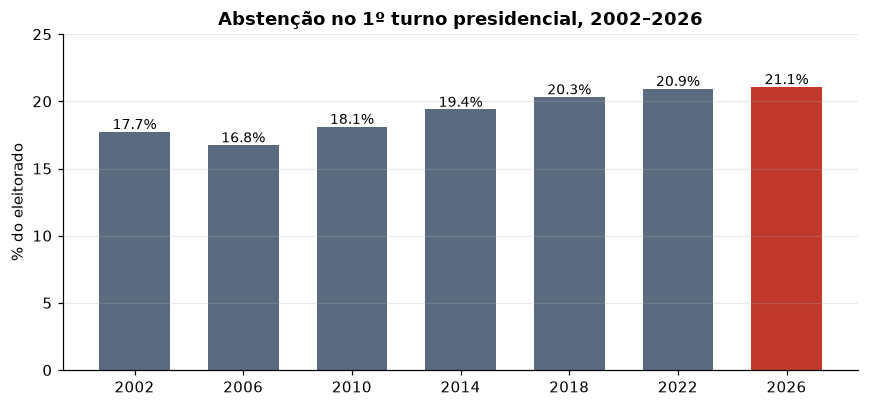

2022→2026: +0.14 p.p. | 2018→2022: +0.62 p.p. | 2006→2026: +4.33 p.p.
Para referência, 2º turno de 2022: 20.58%


In [3]:
h = pd.read_csv(DATA / "serie_historica.csv"); h = h[h.turno == 1][["ano", "aptos", "abst"]]
rec = (t1.groupby("ano")[["QT_APTOS", "QT_ABSTENCOES"]].sum().reset_index()
       .rename(columns={"QT_APTOS": "aptos", "QT_ABSTENCOES": "abst"}))
serie = pd.concat([h, rec]).reset_index(drop=True)
serie["abst_pct"] = pct(serie.abst, serie.aptos)

fig, ax = plt.subplots(figsize=(8, 3.8))
b = ax.bar(serie.ano.astype(str), serie.abst_pct, color=[COR["abst"]] * (len(serie) - 1) + [COR["lula"]], width=.65)
for r, v in zip(b, serie.abst_pct): ax.text(r.get_x() + r.get_width() / 2, v + .2, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_ylim(0, 25); ax.set_ylabel("% do eleitorado"); ax.grid(axis="x", visible=False)
ax.set_title("Abstenção no 1º turno presidencial, 2002–2026")
plt.tight_layout(); plt.show()

v = serie.set_index("ano").abst_pct
print(f"2022→2026: {v[2026]-v[2022]:+.2f} p.p. | 2018→2022: {v[2022]-v[2018]:+.2f} p.p. | 2006→2026: {v[2026]-v[2006]:+.2f} p.p.")
r2 = zona[(zona.ano == 2022) & (zona.NR_TURNO == 2)]
print(f"Para referência, 2º turno de 2022: {pct(r2.QT_ABSTENCOES.sum(), r2.QT_APTOS.sum()):.2f}%")

**Leitura.** A abstenção de 2026 (21,08%) é praticamente a de 2022 (20,95%): **+0,14 p.p.** Não houve salto. O que existe é uma
**tendência de longo prazo**: de 16,8% em 2006 para 21,1% em 2026 (+4,3 p.p. em 20 anos). Portanto "por que tanta abstenção?"
tem duas respostas distintas: (a) por que ela é estruturalmente alta e crescente — seção 6 — e (b) por que o resultado
*surpreendeu* — que, como se verá, **não** parece ser a abstenção (seções 4 e 5).

## 3. Onde ela subiu e onde caiu: estados

O texto destaca que Lula não ganhou em nenhum dos quatro estados de maior abstenção. Isso é verdade, mas precisa de base de comparação.

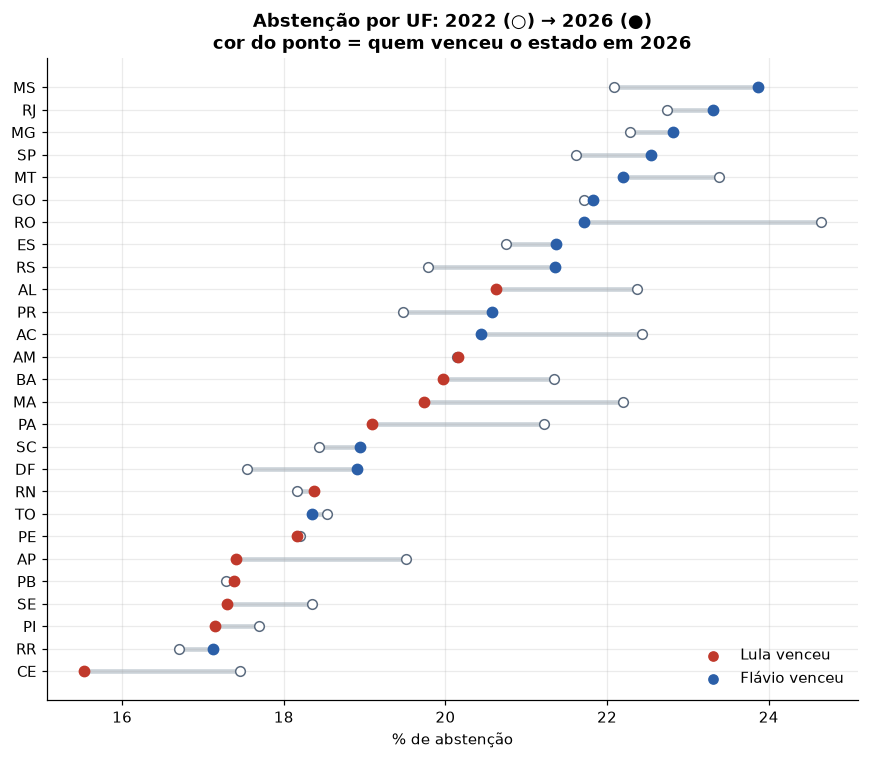

,abst_22,abst_26,venceu_22,venceu_26,delta
SG_UF,,,,,
MS,22.08,23.87,Bolsonaro,Flávio,1.78
RJ,22.74,23.32,Bolsonaro,Flávio,0.57
MG,22.28,22.81,Lula,Flávio,0.53
SP,21.61,22.54,Bolsonaro,Flávio,0.93


In [4]:
u = t1_br.groupby(["SG_UF", "ano"])[["QT_APTOS", "QT_ABSTENCOES", "lula", "pl"]].sum().unstack("ano")
uf = pd.DataFrame({
    "abst_22": pct(u[("QT_ABSTENCOES", 2022)], u[("QT_APTOS", 2022)]),
    "abst_26": pct(u[("QT_ABSTENCOES", 2026)], u[("QT_APTOS", 2026)]),
    "venceu_22": np.where(u[("lula", 2022)] > u[("pl", 2022)], "Lula", "Bolsonaro"),
    "venceu_26": np.where(u[("lula", 2026)] > u[("pl", 2026)], "Lula", "Flávio"),
})
uf["delta"] = uf.abst_26 - uf.abst_22
uf = uf.sort_values("abst_26", ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(uf))[::-1]
for yi, (_, r) in zip(y, uf.iterrows()):
    ax.plot([r.abst_22, r.abst_26], [yi, yi], color=COR["bn"], lw=3, zorder=1)
    ax.scatter(r.abst_22, yi, color="white", edgecolor=COR["abst"], s=40, zorder=2)
    ax.scatter(r.abst_26, yi, color=COR["lula"] if r.venceu_26 == "Lula" else COR["pl"], s=45, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(uf.index); ax.set_xlabel("% de abstenção")
ax.set_title("Abstenção por UF: 2022 (○) → 2026 (●)\ncor do ponto = quem venceu o estado em 2026")
ax.scatter([], [], color=COR["lula"], label="Lula venceu"); ax.scatter([], [], color=COR["pl"], label="Flávio venceu")
ax.legend(loc="lower right", frameon=False); plt.tight_layout(); plt.show()

uf.head(4).round(2)

In [5]:
print("UFs onde a abstenção SUBIU:", (uf.delta > 0).sum(), "| CAIU:", (uf.delta < 0).sum())
print("Mudaram de vencedor 2022→2026:", uf[uf.venceu_22.replace({'Bolsonaro':'x','Lula':'Lula'}) != uf.venceu_26.replace({'Flávio':'x','Lula':'Lula'})].index.tolist())
print()
print("Δ abstenção (p.p.), UFs que Lula venceu em 2026 :", round(wavg(uf[uf.venceu_26=='Lula'].delta, np.ones((uf.venceu_26=='Lula').sum())), 2), "(média simples)")
print("Δ abstenção (p.p.), UFs que Flávio venceu em 2026:", round(wavg(uf[uf.venceu_26!='Lula'].delta, np.ones((uf.venceu_26!='Lula').sum())), 2), "(média simples)")

UFs onde a abstenção SUBIU: 14 | CAIU: 13
Mudaram de vencedor 2022→2026: ['MG', 'TO']

Δ abstenção (p.p.), UFs que Lula venceu em 2026 : -1.09 (média simples)
Δ abstenção (p.p.), UFs que Flávio venceu em 2026: 0.21 (média simples)


**Leitura.** Dos quatro estados de maior abstenção, só **MG** mudou de lado (Lula venceu em 2022, perdeu em 2026) — e lá a abstenção subiu apenas
~0,5 p.p. Em SP, RJ e MS o vencedor já era Bolsonaro em 2022. (No país, só MG e TO mudaram de lado.) Isto é: "Lula não ganhou nos quatro estados de maior abstenção" é em boa parte
uma coincidência geográfica (são estados grandes e de votação bolsonarista), não evidência de causalidade.
O padrão é **regional**: a abstenção sobe em vários estados do Sul/Sudeste/Centro-Oeste e **cai** no Norte/Nordeste (CE −1,9, MA −2,5, PA −2,1 p.p.). Nos estados que Lula venceu em 2026 a abstenção *caiu* em média 1,1 p.p.; nos que Flávio venceu, subiu 0,2 p.p.

## 4. Teste central: a abstenção subiu mais onde Lula era mais forte?

Unidade: **município** (5.564 com dado nos dois anos; exterior excluído). Para cada um calculo Δ abstenção (2026−2022, em p.p.) e a % de Lula nos votos válidos em 2022.
Se a hipótese "a abstenção explica a perda" fosse verdadeira, a abstenção deveria ter subido mais nos municípios mais lulistas.

5564 municípios


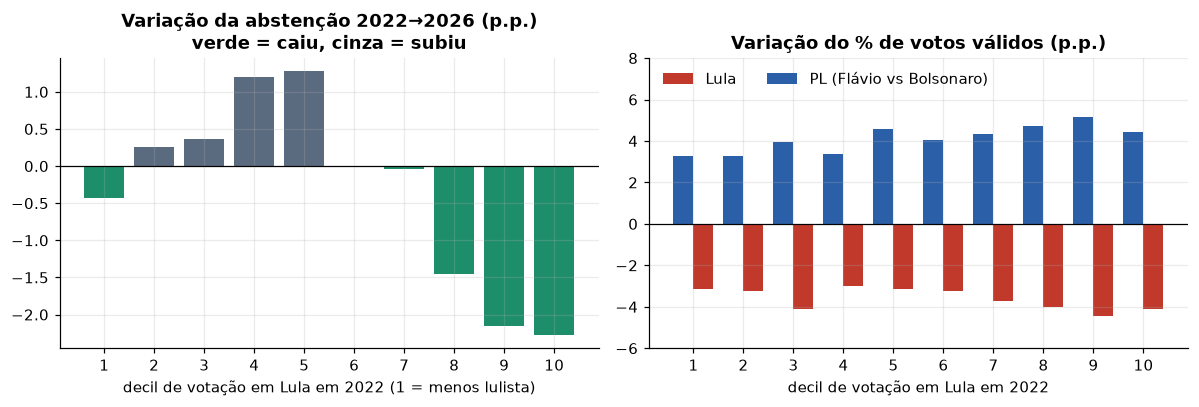

,lula22 (% válidos),abst22,abst26,Δ abstenção (p.p.),Δ Lula (p.p. válidos),Δ Flávio vs Bolsonaro (p.p. válidos)
decil,,,,,,
1,26.51,21.08,20.61,-0.42,-3.13,3.26
2,34.17,20.62,20.82,0.25,-3.22,3.28
3,39.12,20.97,21.29,0.36,-4.09,3.95
4,43.89,21.15,22.31,1.20,-3.00,3.35
5,48.73,21.08,22.32,1.28,-3.13,4.56
6,55.26,18.77,18.72,-0.01,-3.25,4.04
7,64.08,19.65,19.54,-0.04,-3.72,4.32
8,70.97,21.12,19.54,-1.45,-4.03,4.73
9,76.67,22.05,19.76,-2.16,-4.44,5.14


In [6]:
m = (t1_br.groupby(["ano", "SG_UF", "CD_MUNICIPIO", "NM_MUNICIPIO"], as_index=False)
     [["QT_APTOS", "QT_ABSTENCOES", "lula", "pl", "outros", "branco", "nulo"]].sum())
w = m.pivot(index=["SG_UF", "CD_MUNICIPIO", "NM_MUNICIPIO"], columns="ano")
w.columns = [f"{a}_{b}" for a, b in w.columns]; w = w.reset_index().dropna()
for y in (2022, 2026):
    w[f"abst{y}"]  = pct(w[f"QT_ABSTENCOES_{y}"], w[f"QT_APTOS_{y}"])
    w[f"val{y}"]   = w[f"lula_{y}"] + w[f"pl_{y}"] + w[f"outros_{y}"]
    w[f"lula_sh{y}"] = pct(w[f"lula_{y}"], w[f"val{y}"])
    w[f"pl_sh{y}"]   = pct(w[f"pl_{y}"], w[f"val{y}"])
w["dabst"] = w.abst2026 - w.abst2022
w["dlula_sh"] = w.lula_sh2026 - w.lula_sh2022
w["dpl_sh"] = w.pl_sh2026 - w.pl_sh2022
w["peso"] = w.QT_APTOS_2026
w["decil"] = pd.qcut(w.lula_sh2022, 10, labels=False) + 1
print(len(w), "municípios")

dec = w.groupby("decil").apply(lambda g: pd.Series({
    "lula22 (% válidos)": wavg(g.lula_sh2022, g.val2022),
    "abst22": wavg(g.abst2022, g.QT_APTOS_2022), "abst26": wavg(g.abst2026, g.QT_APTOS_2026),
    "Δ abstenção (p.p.)": wavg(g.dabst, g.peso),
    "Δ Lula (p.p. válidos)": wavg(g.dlula_sh, g.val2026),
    "Δ Flávio vs Bolsonaro (p.p. válidos)": wavg(g.dpl_sh, g.val2026)}))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
cols = [COR["pos"] if v < 0 else COR["abst"] for v in dec["Δ abstenção (p.p.)"]]
axs[0].bar(dec.index, dec["Δ abstenção (p.p.)"], color=cols); axs[0].axhline(0, color="k", lw=.8)
axs[0].set_title("Variação da abstenção 2022→2026 (p.p.)\nverde = caiu, cinza = subiu"); axs[0].set_xlabel("decil de votação em Lula em 2022 (1 = menos lulista)")
axs[1].bar(dec.index, dec["Δ Lula (p.p. válidos)"], color=COR["lula"], width=.4, label="Lula", align="edge")
axs[1].bar(dec.index, dec["Δ Flávio vs Bolsonaro (p.p. válidos)"], color=COR["pl"], width=-.4, label="PL (Flávio vs Bolsonaro)", align="edge")
axs[1].axhline(0, color="k", lw=.8); axs[1].set_ylim(-6, 8); axs[1].legend(frameon=False, ncol=2, loc="upper left")
axs[1].set_title("Variação do % de votos válidos (p.p.)"); axs[1].set_xlabel("decil de votação em Lula em 2022")
for a in axs: a.set_xticks(range(1, 11))
plt.tight_layout(); plt.show()
dec.round(2)

**Leitura.** O padrão é o **oposto** do que a hipótese preveria: nos 3 decis mais lulistas, a abstenção **caiu** ~1,5 a 2,3 p.p.;
ela subiu nos decis intermediários (municípios equilibrados em 2022, +1,2 p.p.). Enquanto isso, o Lula perdeu de 3 a 4,5 p.p. de votos válidos
**em todos os decis** — inclusive onde a abstenção caiu. Um padrão uniforme de perda que independe da abstenção é típico de **mudança de preferência**, não de comparecimento.

Abaixo, a regressão (ponderada por eleitorado, erros robustos) para confirmar que isso não é artefato de estado.

In [7]:
def fit(f, d=None):
    d = w if d is None else d
    return smf.wls(f, data=d, weights=d.peso).fit(cov_type="HC1")

# variação do perfil do eleitorado 2022→2026 (usada como controle no modelo 3)
def _shares(ano):
    p = pe[pe.ano == ano]; tot = p.groupby("CD_MUNICIPIO").QT_ELEITORES.sum()
    s = lambda mask: 100 * p[mask].groupby("CD_MUNICIPIO").QT_ELEITORES.sum() / tot
    return pd.DataFrame({"p1617": s(p.faixa == "16-17"), "p70": s(p.faixa == "70+"),
                         "pbaixa": s(p.escol.isin(["Analfabeto", "Lê/escreve"])), "psup": s(p.escol == "Superior"),
                         "pbio": 100 * p.groupby("CD_MUNICIPIO").QT_ELEITORES_BIOMETRIA.sum() / tot}).fillna(0)
pe = pd.read_parquet(DATA / "perfil_eleitorado.parquet"); pe = pe[pe.SG_UF != "ZZ"]
dperf = (_shares(2026) - _shares(2022)).add_prefix("d")
w = w.merge(dperf, left_on="CD_MUNICIPIO", right_index=True, how="left")

mods = {
    "(1) bivariado":                       fit("dabst ~ lula_sh2022"),
    "(2) + efeito fixo de UF":             fit("dabst ~ lula_sh2022 + C(SG_UF)"),
    "(3) + UF + Δ perfil do eleitorado":   fit("dabst ~ lula_sh2022 + C(SG_UF) + dp1617 + dp70 + dpbaixa + dpsup + dpbio"),
}
lin = pd.DataFrame({k: [r.params["lula_sh2022"], r.bse["lula_sh2022"], r.pvalues["lula_sh2022"], r.rsquared]
                    for k, r in mods.items()}, index=["coef. (p.p. por p.p. de Lula 2022)", "erro-padrão", "p-valor", "R²"]).T
print("Δ abstenção ~ % Lula em 2022 (município, pesos = eleitorado 2026)")
lin.round(4)

Δ abstenção ~ % Lula em 2022 (município, pesos = eleitorado 2026)


,coef. (p.p. por p.p. de Lula 2022),erro-padrão,p-valor,R²
(1) bivariado,-0.0389,0.0043,0.0000,0.0627
(2) + efeito fixo de UF,-0.0038,0.0090,0.6716,0.2289
(3) + UF + Δ perfil do eleitorado,0.0274,0.0033,0.0000,0.7640


**Leitura honesta dos três modelos:**

* **(1) Sem controles:** coeficiente negativo e significativo (−0,04): cada +10 p.p. de Lula em 2022 ↔ ~0,4 p.p. **a menos** de abstenção.
* **(2) Comparando municípios do mesmo estado:** o coeficiente **some** (≈ 0, p = 0,67). Ou seja, o padrão do modelo 1 é sobretudo *entre estados* (a abstenção caiu no Nordeste, onde Lula é forte).
* **(3) Controlando também a mudança de perfil do eleitorado:** o coeficiente vira **levemente positivo** (+0,027: +10 p.p. de Lula ↔ +0,27 p.p. de abstenção). Efeito pequeno e que não é robusto entre especificações.

Em nenhuma especificação há um efeito grande de "abstenção concentrada nos redutos lulistas". A magnitude máxima possível é testada na seção 5.3.

In [8]:
# Robustez: dentro das cidades — por zona eleitoral (mesma zona nos dois anos, eleitorado estável ±25%)
zz = (t1_br.groupby(["ano", "CD_MUNICIPIO", "NR_ZONA"], as_index=False)[["QT_APTOS", "QT_ABSTENCOES", "lula", "pl", "outros"]].sum())
zw = zz.pivot(index=["CD_MUNICIPIO", "NR_ZONA"], columns="ano"); zw.columns = [f"{a}_{b}" for a, b in zw.columns]; zw = zw.dropna().reset_index()
zw = zw[(zw.QT_APTOS_2026 / zw.QT_APTOS_2022).between(.75, 1.25)]
zw["abst22"] = pct(zw.QT_ABSTENCOES_2022, zw.QT_APTOS_2022); zw["abst26"] = pct(zw.QT_ABSTENCOES_2026, zw.QT_APTOS_2026)
zw["dabst"] = zw.abst26 - zw.abst22
zw["lula_sh2022"] = pct(zw.lula_2022, zw.lula_2022 + zw.pl_2022 + zw.outros_2022)
zw["peso"] = zw.QT_APTOS_2026
zw = zw.merge(t1_br[["CD_MUNICIPIO", "SG_UF"]].drop_duplicates(), on="CD_MUNICIPIO")
for nome, f in [("sem controles", "dabst ~ lula_sh2022"), ("com efeito fixo de UF", "dabst ~ lula_sh2022 + C(SG_UF)")]:
    r = smf.wls(f, data=zw, weights=zw.peso).fit(cov_type="HC1")
    print(f"{len(zw):,} zonas, {nome:22s} coef = {r.params['lula_sh2022']:+.4f} (EP {r.bse['lula_sh2022']:.4f}), p = {r.pvalues['lula_sh2022']:.3g}")

6,021 zonas, sem controles          coef = -0.0362 (EP 0.0025), p = 1.51e-46
6,021 zonas, com efeito fixo de UF  coef = -0.0015 (EP 0.0046), p = 0.75


Mesma história por zona eleitoral: negativo sem controles; com UF fixa, o efeito encolhe/desaparece. A hipótese "a abstenção subiu nas áreas lulistas" **não encontra apoio** nos dados do TSE, em nenhuma das duas escalas.

> **Limite:** isto é uma análise ecológica (agregados). Não identifica *indivíduos*; mostra que, no agregado, a geografia da abstenção não é a geografia que explicaria a perda do Lula.

## 5. Votos que mudaram de lado × votos que sumiram

### 5.1 Contabilidade nacional (1º turno 2022 → 1º turno 2026)

In [9]:
a22 = t1[t1.ano == 2022].sum(numeric_only=True); a26 = t1[t1.ano == 2026].sum(numeric_only=True)
acc = pd.DataFrame({
    "2022": [a22.QT_APTOS, a22.lula, a22.pl, a22.outros, a22.branco + a22.nulo, a22.QT_ABSTENCOES],
    "2026": [a26.QT_APTOS, a26.lula, a26.pl, a26.outros, a26.branco + a26.nulo, a26.QT_ABSTENCOES]},
    index=["Eleitores aptos", "Lula", "PL (Bolsonaro → Flávio)", "Outros candidatos", "Brancos + nulos", "Abstenções"])
acc["Δ"] = acc["2026"] - acc["2022"]
acc["Δ em p.p. do eleitorado"] = pct(acc["2026"], a26.QT_APTOS) - pct(acc["2022"], a22.QT_APTOS)
acc.iloc[0, 3] = np.nan
acc.style.format({"2022": "{:,.0f}", "2026": "{:,.0f}", "Δ": "{:+,.0f}", "Δ em p.p. do eleitorado": "{:+.2f}"}, na_rep="—")

,2022,2026,Δ,Δ em p.p. do eleitorado
Eleitores aptos,"156,454,011","158,745,502","+2,291,491",—
Lula,"57,259,504","53,879,538","-3,379,966",-2.66
PL (Bolsonaro → Flávio),"51,072,345","56,104,503","+5,032,158",+2.70
Outros candidatos,"9,897,870","9,321,993","-575,877",-0.45
Brancos + nulos,"5,452,653","5,969,801","+517,148",+0.28
Abstenções,"32,770,982","33,469,244","+698,262",+0.14


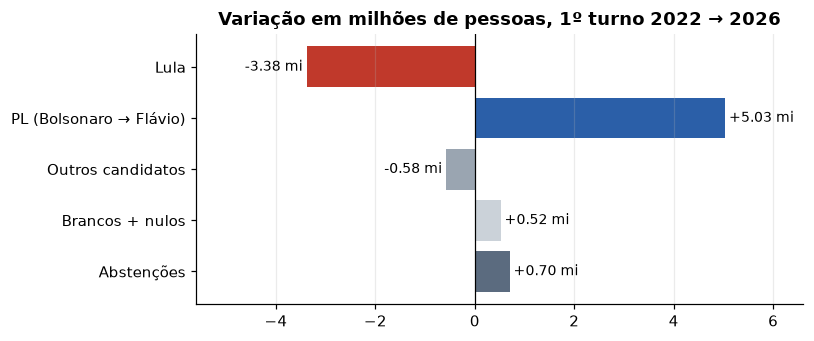

In [10]:
d = acc["Δ"].drop("Eleitores aptos") / 1e6
fig, ax = plt.subplots(figsize=(7.5, 3.2))
cc = [COR["lula"], COR["pl"], COR["outros"], COR["bn"], COR["abst"]]
ax.barh(d.index[::-1], d.values[::-1], color=cc[::-1])
for i, v in enumerate(d.values[::-1]): ax.text(v + (.08 if v > 0 else -.08), i, f"{v:+.2f} mi", va="center", ha="left" if v > 0 else "right", fontsize=9)
ax.axvline(0, color="k", lw=.8); ax.set_xlim(-5.6, 6.6); ax.grid(axis="y", visible=False)
ax.set_title("Variação em milhões de pessoas, 1º turno 2022 → 2026"); plt.tight_layout(); plt.show()

**Leitura.** O eleitorado cresceu **+2,3 mi**. A abstenção subiu **+0,7 mi**. Já o Lula perdeu **−3,4 mi** de votos e a direita (Bolsonaro → Flávio) ganhou **+5,0 mi**.
A mudança de votos entre candidatos (−3,4 mi e +5,0 mi) é **muito maior** que a variação no número de abstenções (+0,7 mi), e a margem final (~2,2 mi) é maior que toda a alta da abstenção.

### 5.2 Onde foi parar a diferença, por decil de lulismo
Para cada decil, a variação de cada categoria em **pontos percentuais do eleitorado** (soma = 0).

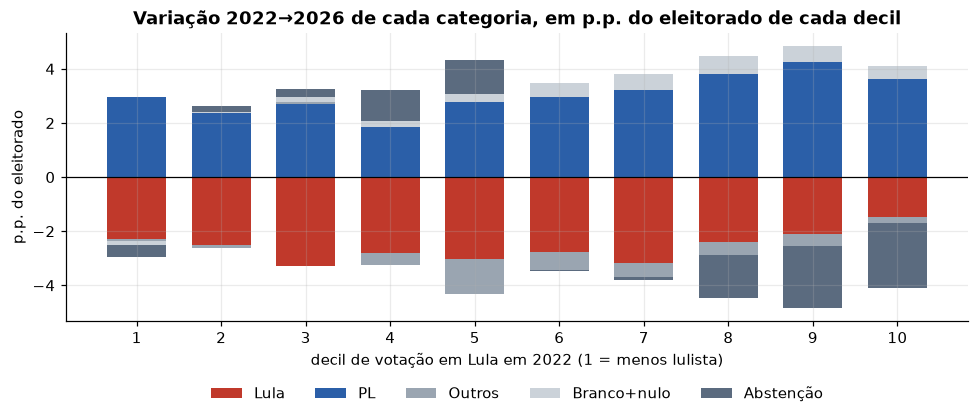

,Lula,PL,Outros,Branco+nulo,Abstenção
decil,,,,,
1,-2.27,2.96,-0.09,-0.13,-0.47
2,-2.52,2.39,-0.09,0.02,0.20
3,-3.27,2.71,0.05,0.19,0.31
4,-2.82,1.85,-0.41,0.23,1.17
5,-3.04,2.77,-1.29,0.32,1.24
6,-2.76,2.96,-0.68,0.52,-0.05
7,-3.18,3.21,-0.52,0.60,-0.11
8,-2.41,3.83,-0.48,0.65,-1.58
9,-2.09,4.24,-0.45,0.59,-2.29


In [11]:
cat = {"lula": "Lula", "pl": "PL", "outros": "Outros", "bn": "Branco+nulo", "abst": "Abstenção"}
rows = []
for k, g in w.groupby("decil"):
    A = lambda y, c: g[c].sum() if isinstance(c, str) else sum(g[x].sum() for x in c)
    r = {}
    for key, cols in [("lula", f"lula_%d"), ("pl", f"pl_%d"), ("outros", f"outros_%d"),
                      ("bn", ("branco_%d", "nulo_%d")), ("abst", f"QT_ABSTENCOES_%d")]:
        get = lambda y: (g[cols % y].sum() if isinstance(cols, str) else sum(g[c % y].sum() for c in cols))
        r[key] = pct(get(2026), g.QT_APTOS_2026.sum()) - pct(get(2022), g.QT_APTOS_2022.sum())
    r["decil"] = k; rows.append(r)
dd = pd.DataFrame(rows).set_index("decil")

fig, ax = plt.subplots(figsize=(9, 4))
pos = np.zeros(len(dd)); neg = np.zeros(len(dd))
for key in ["lula", "pl", "outros", "bn", "abst"]:
    v = dd[key].values; base = np.where(v >= 0, pos, neg)
    ax.bar(dd.index, v, bottom=base, color=COR[key], label=cat[key], width=.7)
    pos += np.where(v >= 0, v, 0); neg += np.where(v < 0, v, 0)
ax.axhline(0, color="k", lw=.8); ax.set_xticks(range(1, 11)); ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(.5, -.18))
ax.set_xlabel("decil de votação em Lula em 2022 (1 = menos lulista)"); ax.set_ylabel("p.p. do eleitorado")
ax.set_title("Variação 2022→2026 de cada categoria, em p.p. do eleitorado de cada decil")
plt.tight_layout(); plt.show()
dd.round(2).rename(columns=cat)

**Leitura.** Em todos os decis o bloco do Lula encolhe e o do PL cresce; a barra cinza-azulada (abstenção) é pequena ou **negativa** nos decis mais lulistas.

### 5.3 Quanto a abstenção poderia, no máximo, explicar?
Dois exercícios deliberadamente generosos com a hipótese "a abstenção explica a perda":

* **Limite superior:** some, município a município, os eleitores adicionais que deixaram de votar (apenas onde a abstenção subiu) e imagine que *todos* teriam votado em Lula.
* **Contrafactual de comparecimento:** reescale os votos de 2026 de cada município para a taxa de comparecimento de 2022, mantendo as proporções entre candidatos.

In [12]:
margem = w.pl_2026.sum() - w.lula_2026.sum()
extra = (np.clip(w.dabst, 0, None) / 100 * w.QT_APTOS_2026).sum()
print(f"Margem Flávio − Lula (sem exterior): {margem:,.0f} votos")
print(f"Limite superior: abstenções 'extras' (onde subiu): {extra:,.0f}  → {100*extra/margem:.0f}% da margem, supondo 100% teriam votado em Lula")

f = (1 - w.abst2022 / 100) / (1 - w.abst2026 / 100)
cf = {c: (w[f"{c}_2026"] * f).sum() for c in ("lula", "pl", "outros")}
tot = sum(cf.values())
print()
print(f"Contrafactual com comparecimento de 2022:  Lula {100*cf['lula']/tot:.2f}%  vs  Flávio {100*cf['pl']/tot:.2f}%  (válidos)")
print(f"Observado em 2026 (sem exterior):          Lula {pct(w.lula_2026.sum(), w.val2026.sum()):.2f}%  vs  Flávio {pct(w.pl_2026.sum(), w.val2026.sum()):.2f}%")
print(f"Margem contrafactual: {cf['pl']-cf['lula']:,.0f} votos (observada: {margem:,.0f})")

Margem Flávio − Lula (sem exterior): 2,236,268 votos
Limite superior: abstenções 'extras' (onde subiu): 1,578,273  → 71% da margem, supondo 100% teriam votado em Lula

Contrafactual com comparecimento de 2022:  Lula 45.05%  vs  Flávio 47.10%  (válidos)
Observado em 2026 (sem exterior):          Lula 45.15%  vs  Flávio 47.03%
Margem contrafactual: 2,450,587 votos (observada: 2,236,268)


**Leitura.** Mesmo na leitura mais favorável, as "abstenções extras" (~1,6 mi, e *só* contando onde subiram — ignorando as quedas em outros municípios) cobririam no máximo ~71% da margem — e só se
**todos** esses eleitores fossem do Lula, o que é implausível. No contrafactual proporcional, com o comparecimento de 2022, **a diferença não encolhe: ela aumenta** (≈ +2,45 mi contra 2,24 mi observados),
porque o comparecimento *subiu* (a abstenção caiu) justamente nos municípios mais lulistas: se tudo tivesse ficado como em 2022, o Lula teria tido menos votos relativos, não mais.
Conclusão: pelos dados do TSE, a **abstenção não explica** a diferença no 1º turno. Foi mudança de preferência.

> **Cuidado:** estes exercícios supõem que abstenção e preferência se distribuem de forma proporcional dentro do município. É o melhor que dados agregados permitem. Inferência ecológica formal (King/Rosen)
> ou pesquisa de painel com os mesmos eleitores seria necessária para ir além.

## 6. Então por que a abstenção é estruturalmente tão alta?

Aqui os dados do TSE por **idade × escolaridade** de 2022 (último arquivo de comparecimento por perfil publicado; o de 2026 ainda não saiu) são essenciais.

### 6.1 O voto é obrigatório para uns e facultativo para outros

2022, 1º turno — eleitores facultativos = 16–17 anos, 70+ e analfabetos
  facultativos:  20.9 mi (13.4% do eleitorado) | abstenção 49.9% | respondem por 31.9% das abstenções
  obrigatórios: 135.5 mi (86.6% do eleitorado) | abstenção 16.4% | respondem por 68.1% das abstenções


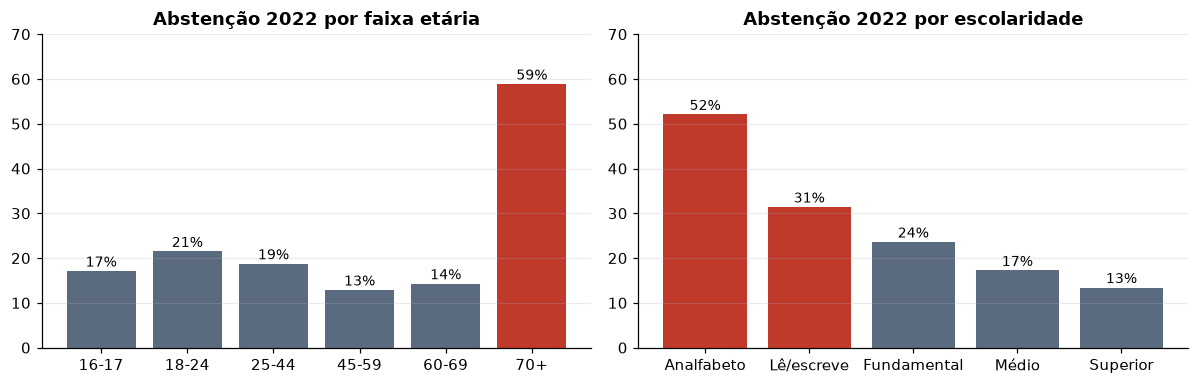

In [13]:
pa = pd.read_parquet(DATA / "perfil_abstencao_2022.parquet")
tot = pa[["QT_APTOS", "QT_ABSTENCAO", "QT_COMPAREC_FACULTATIVO", "QT_ABST_FACULTATIVO",
          "QT_COMPAREC_OBRIGATORIO", "QT_ABST_OBRIGATORIO"]].sum()
fac_n = tot.QT_COMPAREC_FACULTATIVO + tot.QT_ABST_FACULTATIVO; obr_n = tot.QT_COMPAREC_OBRIGATORIO + tot.QT_ABST_OBRIGATORIO
print("2022, 1º turno — eleitores facultativos = 16–17 anos, 70+ e analfabetos")
print(f"  facultativos: {fac_n/1e6:5.1f} mi ({pct(fac_n, tot.QT_APTOS):.1f}% do eleitorado) | abstenção {pct(tot.QT_ABST_FACULTATIVO, fac_n):.1f}% | respondem por {pct(tot.QT_ABST_FACULTATIVO, tot.QT_ABSTENCAO):.1f}% das abstenções")
print(f"  obrigatórios: {obr_n/1e6:5.1f} mi ({pct(obr_n, tot.QT_APTOS):.1f}% do eleitorado) | abstenção {pct(tot.QT_ABST_OBRIGATORIO, obr_n):.1f}% | respondem por {pct(tot.QT_ABST_OBRIGATORIO, tot.QT_ABSTENCAO):.1f}% das abstenções")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [6, 6]})
for ax, col, ordem, tit in [(axs[0], "faixa", ["16-17", "18-24", "25-44", "45-59", "60-69", "70+"], "por faixa etária"),
                            (axs[1], "escol", ["Analfabeto", "Lê/escreve", "Fundamental", "Médio", "Superior"], "por escolaridade")]:
    g = pa[pa[col].isin(ordem)].groupby(col)[["QT_APTOS", "QT_ABSTENCAO"]].sum().loc[ordem]
    r = pct(g.QT_ABSTENCAO, g.QT_APTOS)
    ax.bar(ordem, r, color=[COR["lula"] if v > 30 else COR["abst"] for v in r])
    for i, v in enumerate(r): ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
    ax.set_ylim(0, 70); ax.set_title(f"Abstenção 2022 {tit}"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Leitura.** Um terço de todas as abstenções vem de apenas ~13% do eleitorado (os facultativos), dos quais **metade** não vota. Idosos 70+ (59%) e analfabetos (52%) são os campeões.
Mas o grupo obrigatório também falta bastante (≈16%). Os dados não medem *por quê*; hipóteses usuais são sanção fraca pela ausência e cadastro defasado (eleitores que mudaram de cidade ou morreram e seguem "aptos") — ambas
sugeridas, **não testadas** aqui.

### 6.2 O que mudou de 2022 para 2026: composição do eleitorado × comportamento

Pergunta: se cada grupo (UF × idade × escolaridade) tivesse a **mesma taxa de abstenção de 2022**, qual seria a abstenção esperada com o eleitorado de 2026? Se for maior que a de 2022, a composição (envelhecimento) empurra a abstenção para cima; o resíduo seria "comportamento".

In [14]:
pe = pd.read_parquet(DATA / "perfil_eleitorado.parquet"); pe = pe[pe.SG_UF != "ZZ"]

def esperada(ano, chaves):
    r = pa[pa.SG_UF != "ZZ"].groupby(["SG_UF"] + chaves)[["QT_APTOS", "QT_ABSTENCAO"]].sum()
    r["taxa"] = r.QT_ABSTENCAO / r.QT_APTOS
    p = pe[pe.ano == ano].groupby(["SG_UF"] + chaves).QT_ELEITORES.sum().rename("n").reset_index()
    p = p.merge(r.taxa.reset_index(), on=["SG_UF"] + chaves, how="left")
    return 100 * (p.n * p.taxa).sum() / p.n.sum()

obs = {y: pct(g.QT_ABSTENCOES.sum(), g.QT_APTOS.sum()) for y, g in t1_br.groupby("ano")}
esq = {"só geografia (UF)": [], "+ idade": ["faixa"], "+ escolaridade": ["escol"], "idade × escolaridade": ["faixa", "escol"]}
comp = pd.DataFrame({k: {"esperada 2022": esperada(2022, c), "esperada 2026 (taxas de 2022)": esperada(2026, c)} for k, c in esq.items()}).T
comp["efeito composição (p.p.)"] = comp["esperada 2026 (taxas de 2022)"] - comp["esperada 2022"]
print(f"Observado (sem exterior): 2022 = {obs[2022]:.2f}% | 2026 = {obs[2026]:.2f}% | Δ = {obs[2026]-obs[2022]:+.2f} p.p.")
comp.round(2)

Observado (sem exterior): 2022 = 20.79% | 2026 = 20.84% | Δ = +0.05 p.p.


,esperada 2022,esperada 2026 (taxas de 2022),efeito composição (p.p.)
só geografia (UF),20.79,20.77,-0.02
+ idade,20.79,21.16,0.37
+ escolaridade,20.79,20.19,-0.60
idade × escolaridade,20.79,20.49,-0.30


In [15]:
efeito = comp.loc["idade × escolaridade", "efeito composição (p.p.)"]
dobs = obs[2026] - obs[2022]
print(f"Efeito do envelhecimento isolado (idade):        {comp.loc['+ idade','efeito composição (p.p.)']:+.2f} p.p.")
print(f"Efeito da maior escolaridade isolado:            {comp.loc['+ escolaridade','efeito composição (p.p.)']:+.2f} p.p.")
print(f"Efeito conjunto de composição (idade × escol.):  {efeito:+.2f} p.p.")
print(f"Variação observada:                              {dobs:+.2f} p.p.")
print(f"Resíduo (comportamento dentro dos grupos):       {dobs-efeito:+.2f} p.p.")

Efeito do envelhecimento isolado (idade):        +0.37 p.p.
Efeito da maior escolaridade isolado:            -0.60 p.p.
Efeito conjunto de composição (idade × escol.):  -0.30 p.p.
Variação observada:                              +0.05 p.p.
Resíduo (comportamento dentro dos grupos):       +0.35 p.p.


**Leitura.** Duas forças contrárias:

* **Envelhecimento** (70+ passou de 9,5% para 10,9% do eleitorado; esse grupo abstém ~59%) empurra a abstenção **para cima**.
* **Mais escolaridade** (analfabetos 4,1% → 3,5%; ensino médio/superior crescendo) empurra **para baixo**.

O efeito líquido da composição é pequeno e **negativo** — se as pessoas tivessem se comportado como em 2022, a abstenção teria *caído*. Como o observado ficou ligeiramente acima, o resíduo
("comportamento": mais gente de cada perfil deixando de ir) é positivo, na ordem de +0,35 p.p. Ou seja, **nem a composição nem o comportamento mudaram muito** — o que reforça que a abstenção de 2026 é essencialmente a de 2022.

### 6.3 Geografia da abstenção: o que distingue um município do outro?
Regressão da abstenção de 2026 (município, ponderada pelo eleitorado) em perfil do eleitorado (TSE) e renda/urbanização (Censo 2022, IBGE).

In [16]:
def shares(ano):
    p = pe[pe.ano == ano]; tot = p.groupby("CD_MUNICIPIO").QT_ELEITORES.sum()
    s = lambda mask: 100 * p[mask].groupby("CD_MUNICIPIO").QT_ELEITORES.sum() / tot
    d = pd.DataFrame({"p1617": s(p.faixa == "16-17"), "p70": s(p.faixa == "70+"),
                      "pbaixa": s(p.escol.isin(["Analfabeto", "Lê/escreve"])), "psup": s(p.escol == "Superior"),
                      "pbio": 100 * p.groupby("CD_MUNICIPIO").QT_ELEITORES_BIOMETRIA.sum() / tot}).fillna(0)
    return d.add_suffix(f"_{ano}")

ib = pd.read_parquet(DATA / "ibge_municipio.parquet")
x = (w.merge(shares(2022), left_on="CD_MUNICIPIO", right_index=True).merge(shares(2026), left_on="CD_MUNICIPIO", right_index=True)
      .merge(ib, on="CD_MUNICIPIO"))
x["lrenda"] = np.log(x.renda); x["lpop"] = np.log(x["pop"]); x = x.dropna(subset=["lrenda", "lpop", "pct_urbano"])
for c in ("p1617", "p70", "pbaixa", "psup", "pbio"): x["d" + c] = x[f"{c}_2026"] - x[f"{c}_2022"]
print(len(x), "municípios com todos os dados")

est = {"só UF": "abst2026 ~ C(SG_UF)",
       "UF + perfil (idade, escolaridade)": "abst2026 ~ C(SG_UF) + p1617_2026 + p70_2026 + pbaixa_2026 + psup_2026",
       "UF + perfil + socioeconômico": "abst2026 ~ C(SG_UF) + p1617_2026 + p70_2026 + pbaixa_2026 + psup_2026 + pct_urbano + lrenda + lpop"}
ms = {k: smf.wls(f, data=x, weights=x.peso).fit(cov_type="HC1") for k, f in est.items()}
print("R² (abstenção 2026 entre municípios):")
for k, r in ms.items(): print(f"  {k:40s} {r.rsquared:.3f}")

full = ms["UF + perfil + socioeconômico"]
nomes = {"p1617_2026": "% eleitores 16–17 anos", "p70_2026": "% eleitores 70+", "pbaixa_2026": "% analfabetos/lê-escreve",
         "psup_2026": "% ensino superior", "pct_urbano": "% população urbana", "lrenda": "ln(renda média do trabalho)", "lpop": "ln(população)"}
tab = pd.DataFrame({"coef": full.params[list(nomes)], "IC95 inf": full.conf_int().loc[list(nomes), 0], "IC95 sup": full.conf_int().loc[list(nomes), 1],
                    "p": full.pvalues[list(nomes)]}).rename(index=nomes)
tab.round(3)

5562 municípios com todos os dados


R² (abstenção 2026 entre municípios):
  só UF                                    0.378
  UF + perfil (idade, escolaridade)        0.523
  UF + perfil + socioeconômico             0.558


,coef,IC95 inf,IC95 sup,p
% eleitores 16–17 anos,0.353,-0.011,0.717,0.057
% eleitores 70+,0.421,0.341,0.502,0.000
% analfabetos/lê-escreve,0.185,0.152,0.219,0.000
% ensino superior,-0.123,-0.170,-0.076,0.000
% população urbana,0.045,0.036,0.054,0.000
ln(renda média do trabalho),0.675,-0.504,1.854,0.262
ln(população),0.228,0.082,0.374,0.002


**Leitura.** Só o estado (UF) explica ~38% da variação da abstenção entre municípios; o perfil de idade e escolaridade acrescenta ~15 pontos de R² (→ 0,52) e renda/urbanização/população só ~3 (→ 0,56).
Mantidos os demais fatores: **+10 p.p. de eleitores 70+ ↔ ≈ +4 p.p. de abstenção**; +10 p.p. de analfabetos/lê-escreve ↔ ≈ +1,9; +10 p.p. com ensino superior ↔ ≈ −1,2.
A renda média perde significância depois de controlar escolaridade.

só UF                      R² = 0.229
UF + Δ % de 70+            R² = 0.721 | +1 p.p. de 70+ ↔ +1.36 p.p. de abstenção
UF + Δ perfil completo     R² = 0.756 | +1 p.p. de 70+ ↔ +0.98 p.p. de abstenção
Efeito mecânico esperado de +1 p.p. de 70+ (taxas de 2022): +0.42 p.p. de abstenção


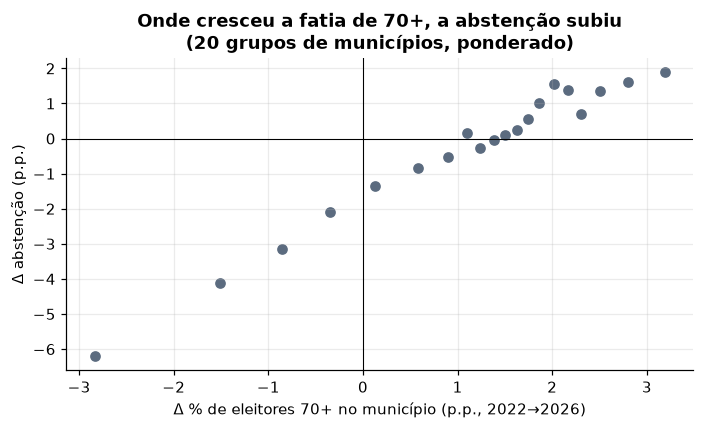

In [17]:
# Mudança de abstenção entre municípios: o que predice onde ela subiu?
mm = {"só UF": "dabst ~ C(SG_UF)",
      "UF + Δ % de 70+": "dabst ~ C(SG_UF) + dp70",
      "UF + Δ perfil completo": "dabst ~ C(SG_UF) + dp1617 + dp70 + dpbaixa + dpsup + dpbio"}
for k, f in mm.items():
    r = smf.wls(f, data=x, weights=x.peso).fit(cov_type="HC1")
    print(f"{k:26s} R² = {r.rsquared:.3f}" + (f" | +1 p.p. de 70+ ↔ {r.params['dp70']:+.2f} p.p. de abstenção" if "dp70" in r.params else ""))

# efeito "mecânico": se cada novo eleitor 70+ abstivesse na taxa dos 70+ em vez da dos demais
g70 = pa[pa.faixa == "70+"][["QT_APTOS", "QT_ABSTENCAO"]].sum(); go = pa[pa.faixa != "70+"][["QT_APTOS", "QT_ABSTENCAO"]].sum()
mec = (g70.QT_ABSTENCAO / g70.QT_APTOS - go.QT_ABSTENCAO / go.QT_APTOS)
print(f"Efeito mecânico esperado de +1 p.p. de 70+ (taxas de 2022): {mec:+.2f} p.p. de abstenção")
fig, ax = plt.subplots(figsize=(6.5, 4))
xs = x.assign(b=pd.qcut(x.dp70, 20, labels=False)).groupby("b").apply(lambda g: pd.Series({"dp70": wavg(g.dp70, g.peso), "dabst": wavg(g.dabst, g.peso)}))
ax.scatter(xs.dp70, xs.dabst, color=COR["abst"]); ax.axhline(0, color="k", lw=.7); ax.axvline(0, color="k", lw=.7)
ax.set_xlabel("Δ % de eleitores 70+ no município (p.p., 2022→2026)"); ax.set_ylabel("Δ abstenção (p.p.)")
ax.set_title("Onde cresceu a fatia de 70+, a abstenção subiu\n(20 grupos de municípios, ponderado)"); plt.tight_layout(); plt.show()

**Leitura.** A variação da fatia de eleitores 70+ é, de longe, o melhor preditor de onde a abstenção subiu: UF sozinha dá R² ≈ 0,23; UF + Δ%70+ chega a ≈ 0,72.
O gradiente estimado (+1 p.p. de 70+ ↔ ≈ +1,0 a +1,4 p.p. de abstenção, conforme os controles) é **bem maior que o efeito mecânico** de composição (≈ +0,4 p.p.). Isso sugere que o envelhecimento do eleitorado nos municípios vem acompanhado de outro fator
(por exemplo, saída de jovens enquanto o cadastro permanece, ou idosos que já não comparecem) — **hipótese não testada**; este dado não separa as explicações.
Nacionalmente os dois efeitos (mais idosos × mais escolaridade) quase se anulam (seção 6.2), por isso o agregado quase não se mexeu.

## 7. O que este notebook **não** cobre (e por quê)

| Fator citado | Status | Observação |
|---|---|---|
| Pesquisas (Quaest, Datafolha) × resultado | **não feito** | Os resultados das pesquisas não fazem parte dos dados do TSE/IBGE usados aqui; exigiria coletar os registros de pesquisa |
| Clima no dia (INMET) | **não feito** | Fora do escopo desta versão; seria um próximo passo (estações × município) |
| Distância ao local de votação | **não feito** | Exigiria geocodificar os locais de votação |
| Transporte público/feriado | **não feito** | Sem dado padronizado por município aqui utilizado |
| Voto dividido (presidente × governador) | **não feito** | Extensão natural: os votos por seção de governador também estão no TSE |
| Cadastro defasado | **não modelado** | Aparece nas hipóteses (6.1 e 6.3), mas não foi medido diretamente |
| Comparecimento por idade em 2026 | **indisponível** | O arquivo `perfil_comparecimento_abstencao_2026` não existia no TSE em 05/10/2026 — usei as taxas de 2022 |

**Limites gerais:** (1) análise ecológica — não prova nada sobre indivíduos; (2) municípios e zonas mudam de tamanho entre os anos (filtrei zonas com eleitorado estável ±25%);
(3) o 2º turno (25/10) ainda não ocorreu; (4) os dados de 2026 são os divulgados em 05/10/2026 e podem ter pequenas correções.

## 8. Conclusões

1. **Os números do texto conferem** com o TSE (diferenças ≤ 0,02 p.p.).
2. **A abstenção de 2026 (21,08%) é praticamente a de 2022 (20,95%)** — +0,14 p.p. É alta, mas é uma tendência de duas décadas (16,8% em 2006), não um salto.
3. **A abstenção não explica a diferença Flávio × Lula no 1º turno.** Ela *caiu* nos municípios mais lulistas (padrão sobretudo entre estados) e subiu nos equilibrados; Lula perdeu 3–4,5 p.p. de votos válidos
   em *todos* os decis; o limite superior generoso das "abstenções extras" cobre ~71% da margem apenas se 100% fossem votos do Lula, e o contrafactual com comparecimento de 2022 deixa a margem *maior* (2,45 mi vs 2,24 mi).
4. **O que os dados mostram é mudança de preferência**: −3,4 mi de votos para Lula e +5,0 mi para a direita, contra +0,7 mi de abstenção.
5. **A abstenção é alta por razões estruturais:** 1/3 vem dos ~13% de eleitores com voto facultativo (que faltam em 50%); até entre os obrigatórios ela é ~16%.
   Entre municípios, o estado explica ~38% da variação, idade/escolaridade mais ~15 pontos; e **onde a fatia de 70+ cresceu, a abstenção subiu bem mais do que a composição sozinha explicaria** (hipótese a investigar: êxodo de jovens/cadastro).
6. **Limites:** o notebook não testa pesquisas, clima, distância, voto dividido (seção 7), e análise ecológica não prova comportamento individual. A "surpresa" é compatível com **pesquisas que erraram a intenção de voto** — hipótese
   que fica como próximo passo.

*Fontes: TSE – Dados Abertos (cdn.tse.jus.br/estatistica/sead/odsele); IBGE – SIDRA/Censo 2022 (servicodados.ibge.gov.br).*